<>:81: SyntaxWarning: invalid escape sequence '\g'
<>:81: SyntaxWarning: invalid escape sequence '\g'
C:\Users\OMEN-PC\AppData\Local\Temp\ipykernel_24652\3344850545.py:81: SyntaxWarning: invalid escape sequence '\g'
  labels=["0 Pairs", "1 Pair", "2 Pairs", "$\geq$3 Pairs"],


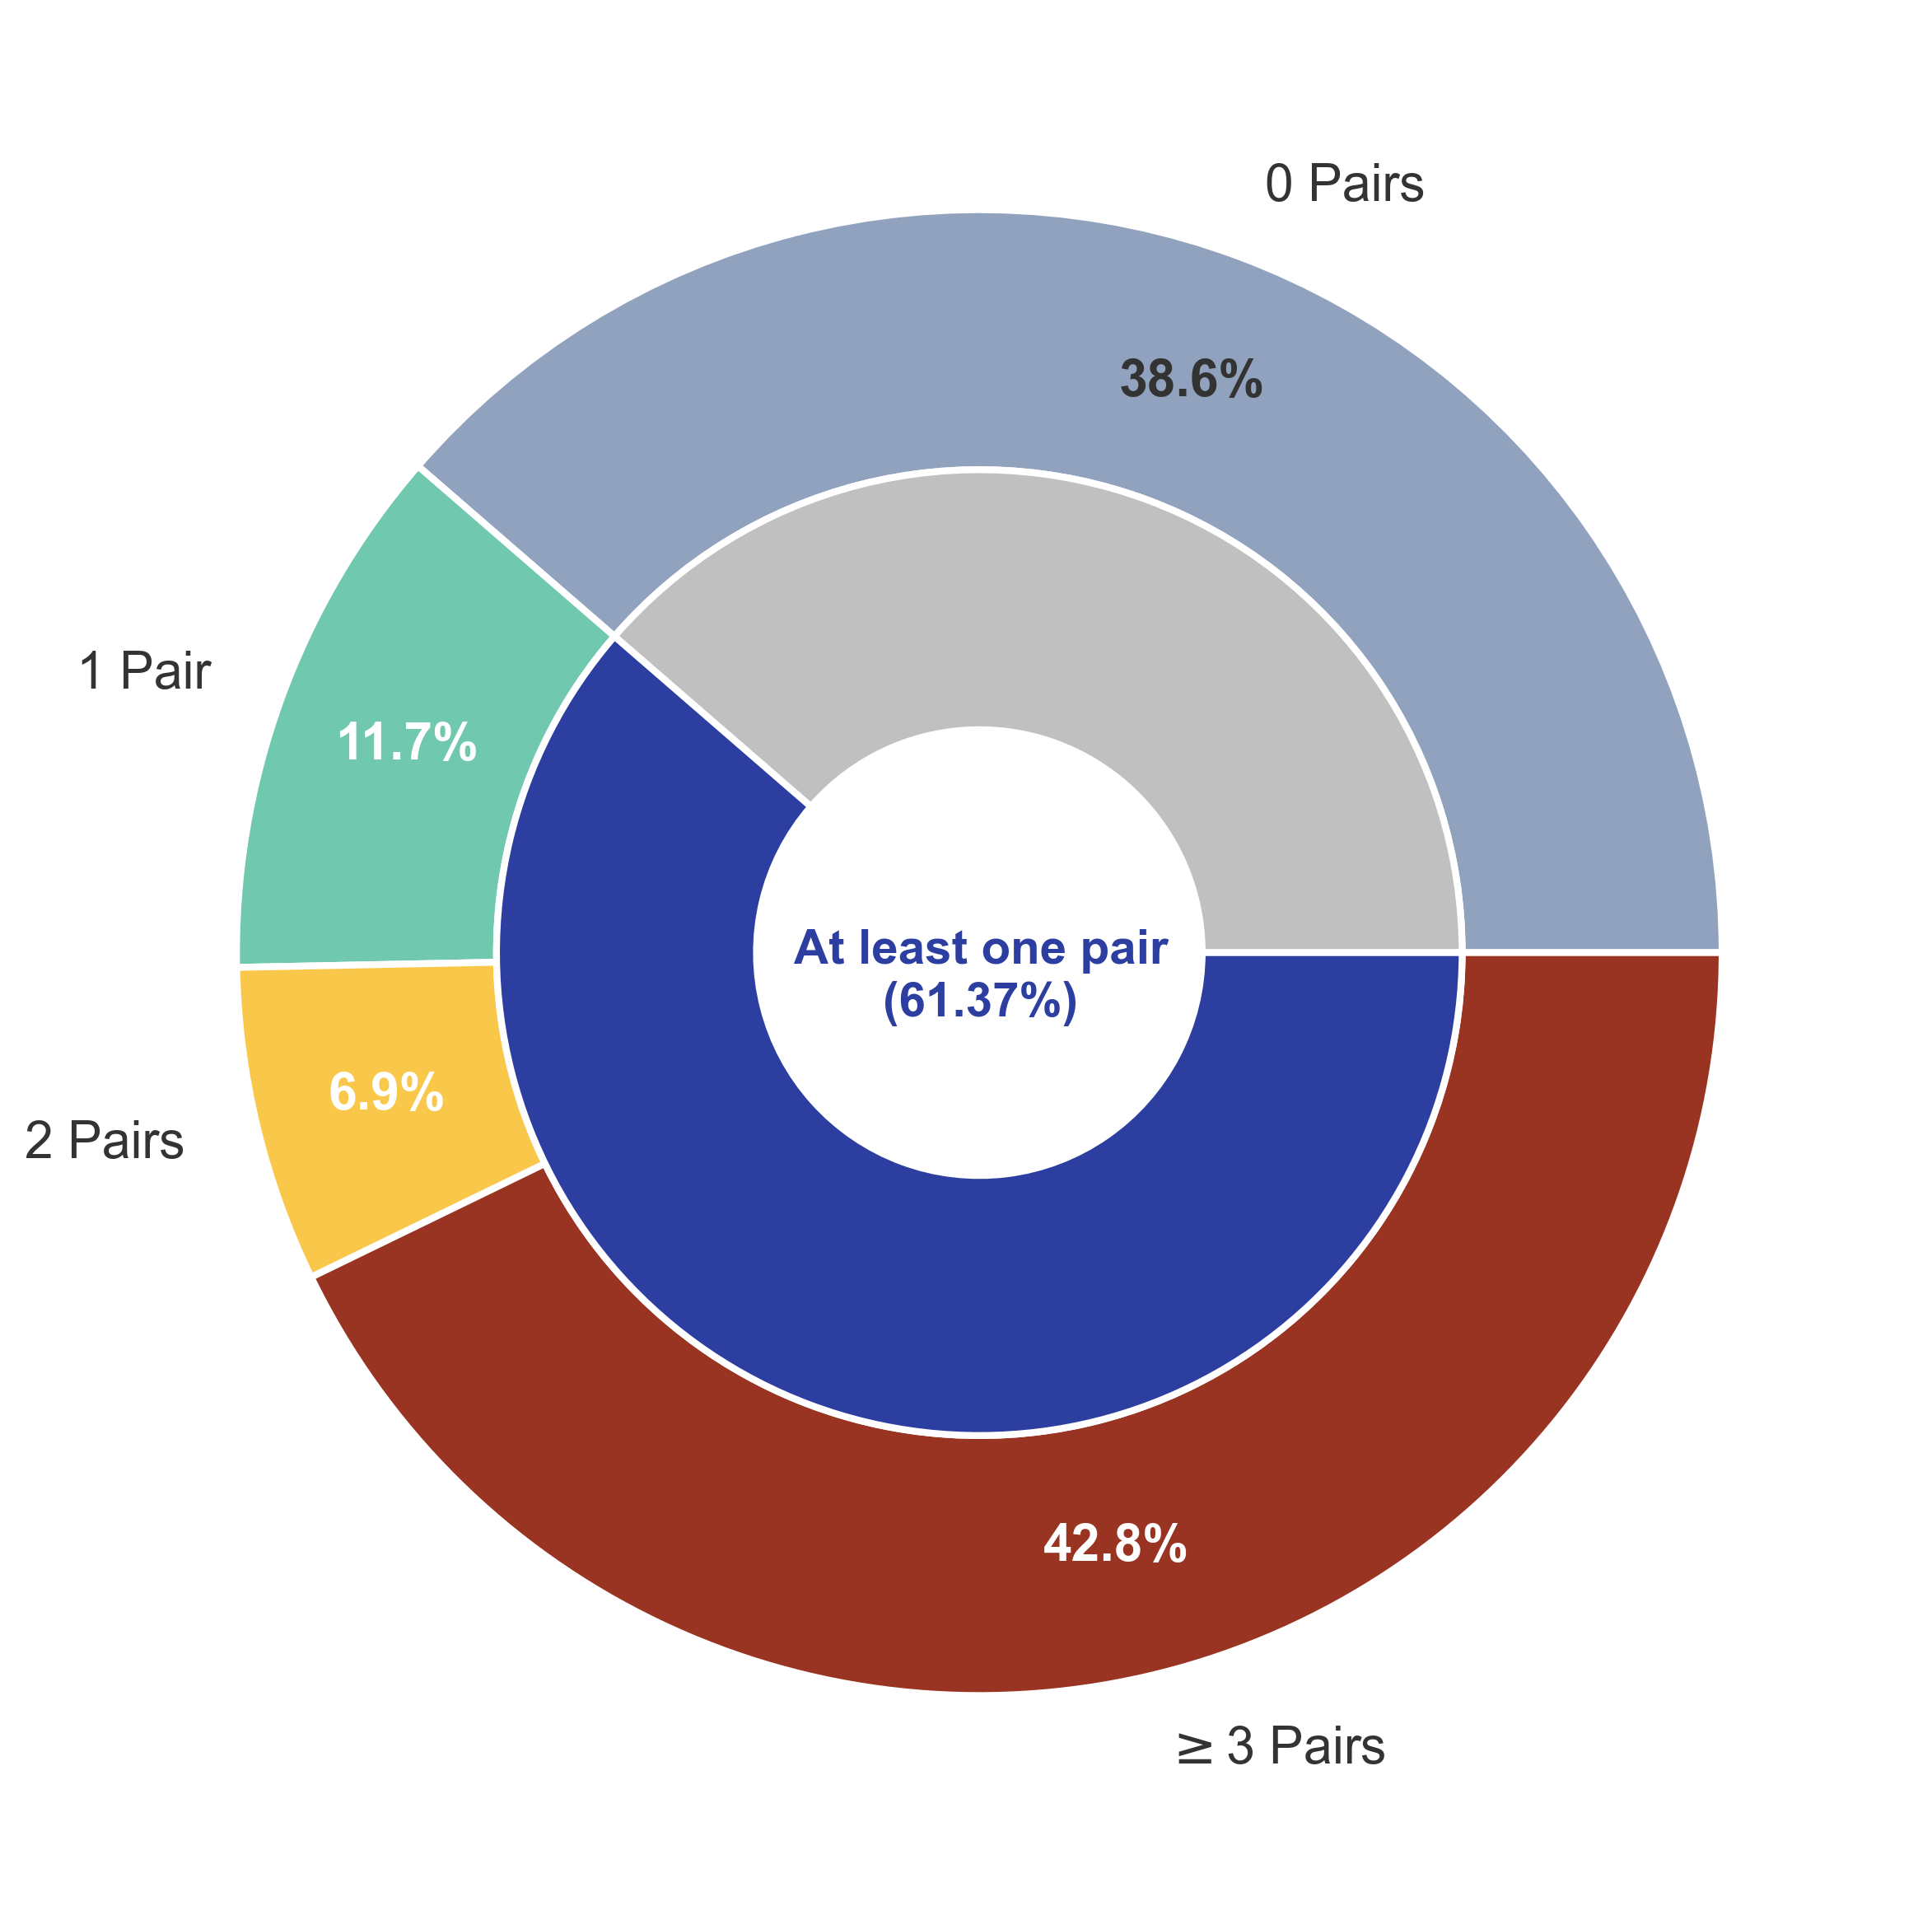

In [22]:
import pandas as pd
import ast
import matplotlib.pyplot as plt
import numpy as np

# ==========================================
# 1. 数据处理与统计
# ==========================================
def count_sl_pairs(val):
    """安全解析 matching_pairs 字符串并计算靶点对数量"""
    if pd.isna(val):
        return 0
    val_str = str(val).strip()
    if val_str in ['', '[]']:
        return 0
    try:
        pairs = ast.literal_eval(val_str)
        if isinstance(pairs, list):
            return len(pairs)
    except:
        pass
    return 0

# 读取数据
df = pd.read_csv('Synthetic_lethal.csv')

# 过滤出 Synergy? == True 的高协同组合 (呼应你论文中的 high phenotypic synergy scores)
# 注意：若CSV中Synergy是字符串'TRUE'，需适配处理
synergy_df = df[df['Synergy?'].astype(str).str.upper() == 'TRUE'].copy()

# 计算每行对应的合成致死靶点对数
synergy_df['pair_count'] = synergy_df['matching_pairs'].apply(count_sl_pairs)

# 统计具体数量
count_0 = len(synergy_df[synergy_df['pair_count'] == 0])
count_1 = len(synergy_df[synergy_df['pair_count'] == 1])
count_2 = len(synergy_df[synergy_df['pair_count'] == 2])
count_3_plus = len(synergy_df[synergy_df['pair_count'] >= 3])

# 【可选】如果你提供的CSV只是部分数据，为了强制图表完全匹配你论文中 14,041/22,881 (61.37%) 的数字，
# 可以取消注释以下代码进行硬编码覆盖（按照真实比例分配外环分布）：
"""
total_synergy = 22881
count_at_least_one = 14041
count_0 = total_synergy - count_at_least_one
# 模拟外环分布比例 (可根据实际情况修改)
count_1 = int(count_at_least_one * 0.5)
count_2 = int(count_at_least_one * 0.3)
count_3_plus = count_at_least_one - count_1 - count_2
"""

# ==========================================
# 2. 顶会风格参数设置 (应用你的专属配色方案)
# ==========================================
plt.rcParams["font.family"] = "sans-serif"
plt.rcParams["font.sans-serif"] = ["Arial", "Helvetica"]
plt.rcParams["pdf.fonttype"] = 42
plt.rcParams["ps.fonttype"] = 42

outer_vals = np.array([count_0, count_1, count_2, count_3_plus])
inner_vals = np.array([count_0, count_1 + count_2 + count_3_plus])

# 应用新配色
# 内环：银灰 (#C0C0C0) vs 深蓝 (#2C3EA0，强调有合成致死靶点)
color_inner = ["#C0C0C0", "#2C3EA0"]
# 外环：灰蓝 (#91A2BF, 0对), 青绿 (#70C9AE, 1对), 亮黄 (#F9C74A, 2对), 深红 (#993322, ≥3对)
color_outer = ["#91A2BF", "#70C9AE", "#F9C74A", "#993322"]

fig, ax = plt.subplots(figsize=(8, 8), dpi=300)
size = 0.35

# ==========================================
# 3. 绘制双层环形图
# ==========================================
# 绘制外环
wedges_outer, texts_outer, autotexts_outer = ax.pie(
    outer_vals,
    radius=1,
    colors=color_outer,
    wedgeprops=dict(width=size, edgecolor="white", linewidth=2),
    labels=["0 Pairs", "1 Pair", "2 Pairs", "$\geq$3 Pairs"],
    autopct=lambda pct: f"{pct:.1f}%" if pct > 5 else "",
    pctdistance=0.82,
    textprops={"fontsize": 15, "color": "#333333"},
)

for autotext in autotexts_outer:
    autotext.set_color("white")
    autotext.set_fontweight("bold")
    autotext.set_fontsize(15)

# 0 Pairs 的灰蓝色底色上，白色字可能不够明显，改为深色
if autotexts_outer[0].get_text() != "":
    autotexts_outer[0].set_color("#333333")

# 绘制内环
pct_at_least_one = (inner_vals[1] / inner_vals.sum()) * 100

wedges_inner, texts_inner = ax.pie(
    inner_vals,
    radius=1 - size,
    colors=color_inner,
    wedgeprops=dict(width=size, edgecolor="white", linewidth=2),
    labels=["", f"At least one pair\n({pct_at_least_one:.2f}%)"],
    labeldistance=0.3,  # 初始粗调
    textprops={"fontsize": 14, "fontweight": "bold", "color": "#111111"},
)

# --- 特殊处理内环标签（核心调整部分） ---
label_obj = texts_inner[1]
label_obj.set_color("#2C3EA0")  # 字体颜色匹配内环深蓝
label_obj.set_ha("center")  # 水平居中对齐
label_obj.set_va("center")  # 垂直居中对齐

# 精确微调位置 (x, y) 坐标，圆心为 (0,0)
# 加上正的 x 偏移量使其向右，调整 y 偏移量使其上下移动
current_x, current_y = label_obj.get_position()
# 根据你的需求，在当前位置基础上向右移动 (例如 +0.15)，向中间微调
label_obj.set_position((current_x + 0.07, current_y + 0.15))

# 如果仍然觉得不够中间，可以直接无视原位置，强制写死坐标，例如：
# label_obj.set_position((0.15, -0.2))

ax.set(aspect="equal")

plt.tight_layout()
# 导出为高分辨率PNG和矢量图PDF (论文提交首选)
plt.savefig(
    "Synthetic_Lethality_Prevalence.png", dpi=300, bbox_inches="tight", transparent=True
)
plt.savefig("Synthetic_Lethality_Prevalence.pdf", bbox_inches="tight", transparent=True)
plt.show()

<>:106: SyntaxWarning: invalid escape sequence '\l'
<>:106: SyntaxWarning: invalid escape sequence '\l'
C:\Users\OMEN-PC\AppData\Local\Temp\ipykernel_24652\3693650068.py:106: SyntaxWarning: invalid escape sequence '\l'
  "$-\log_{10}(P\text{-value})$", fontsize=14, fontweight="bold", color="#333333"


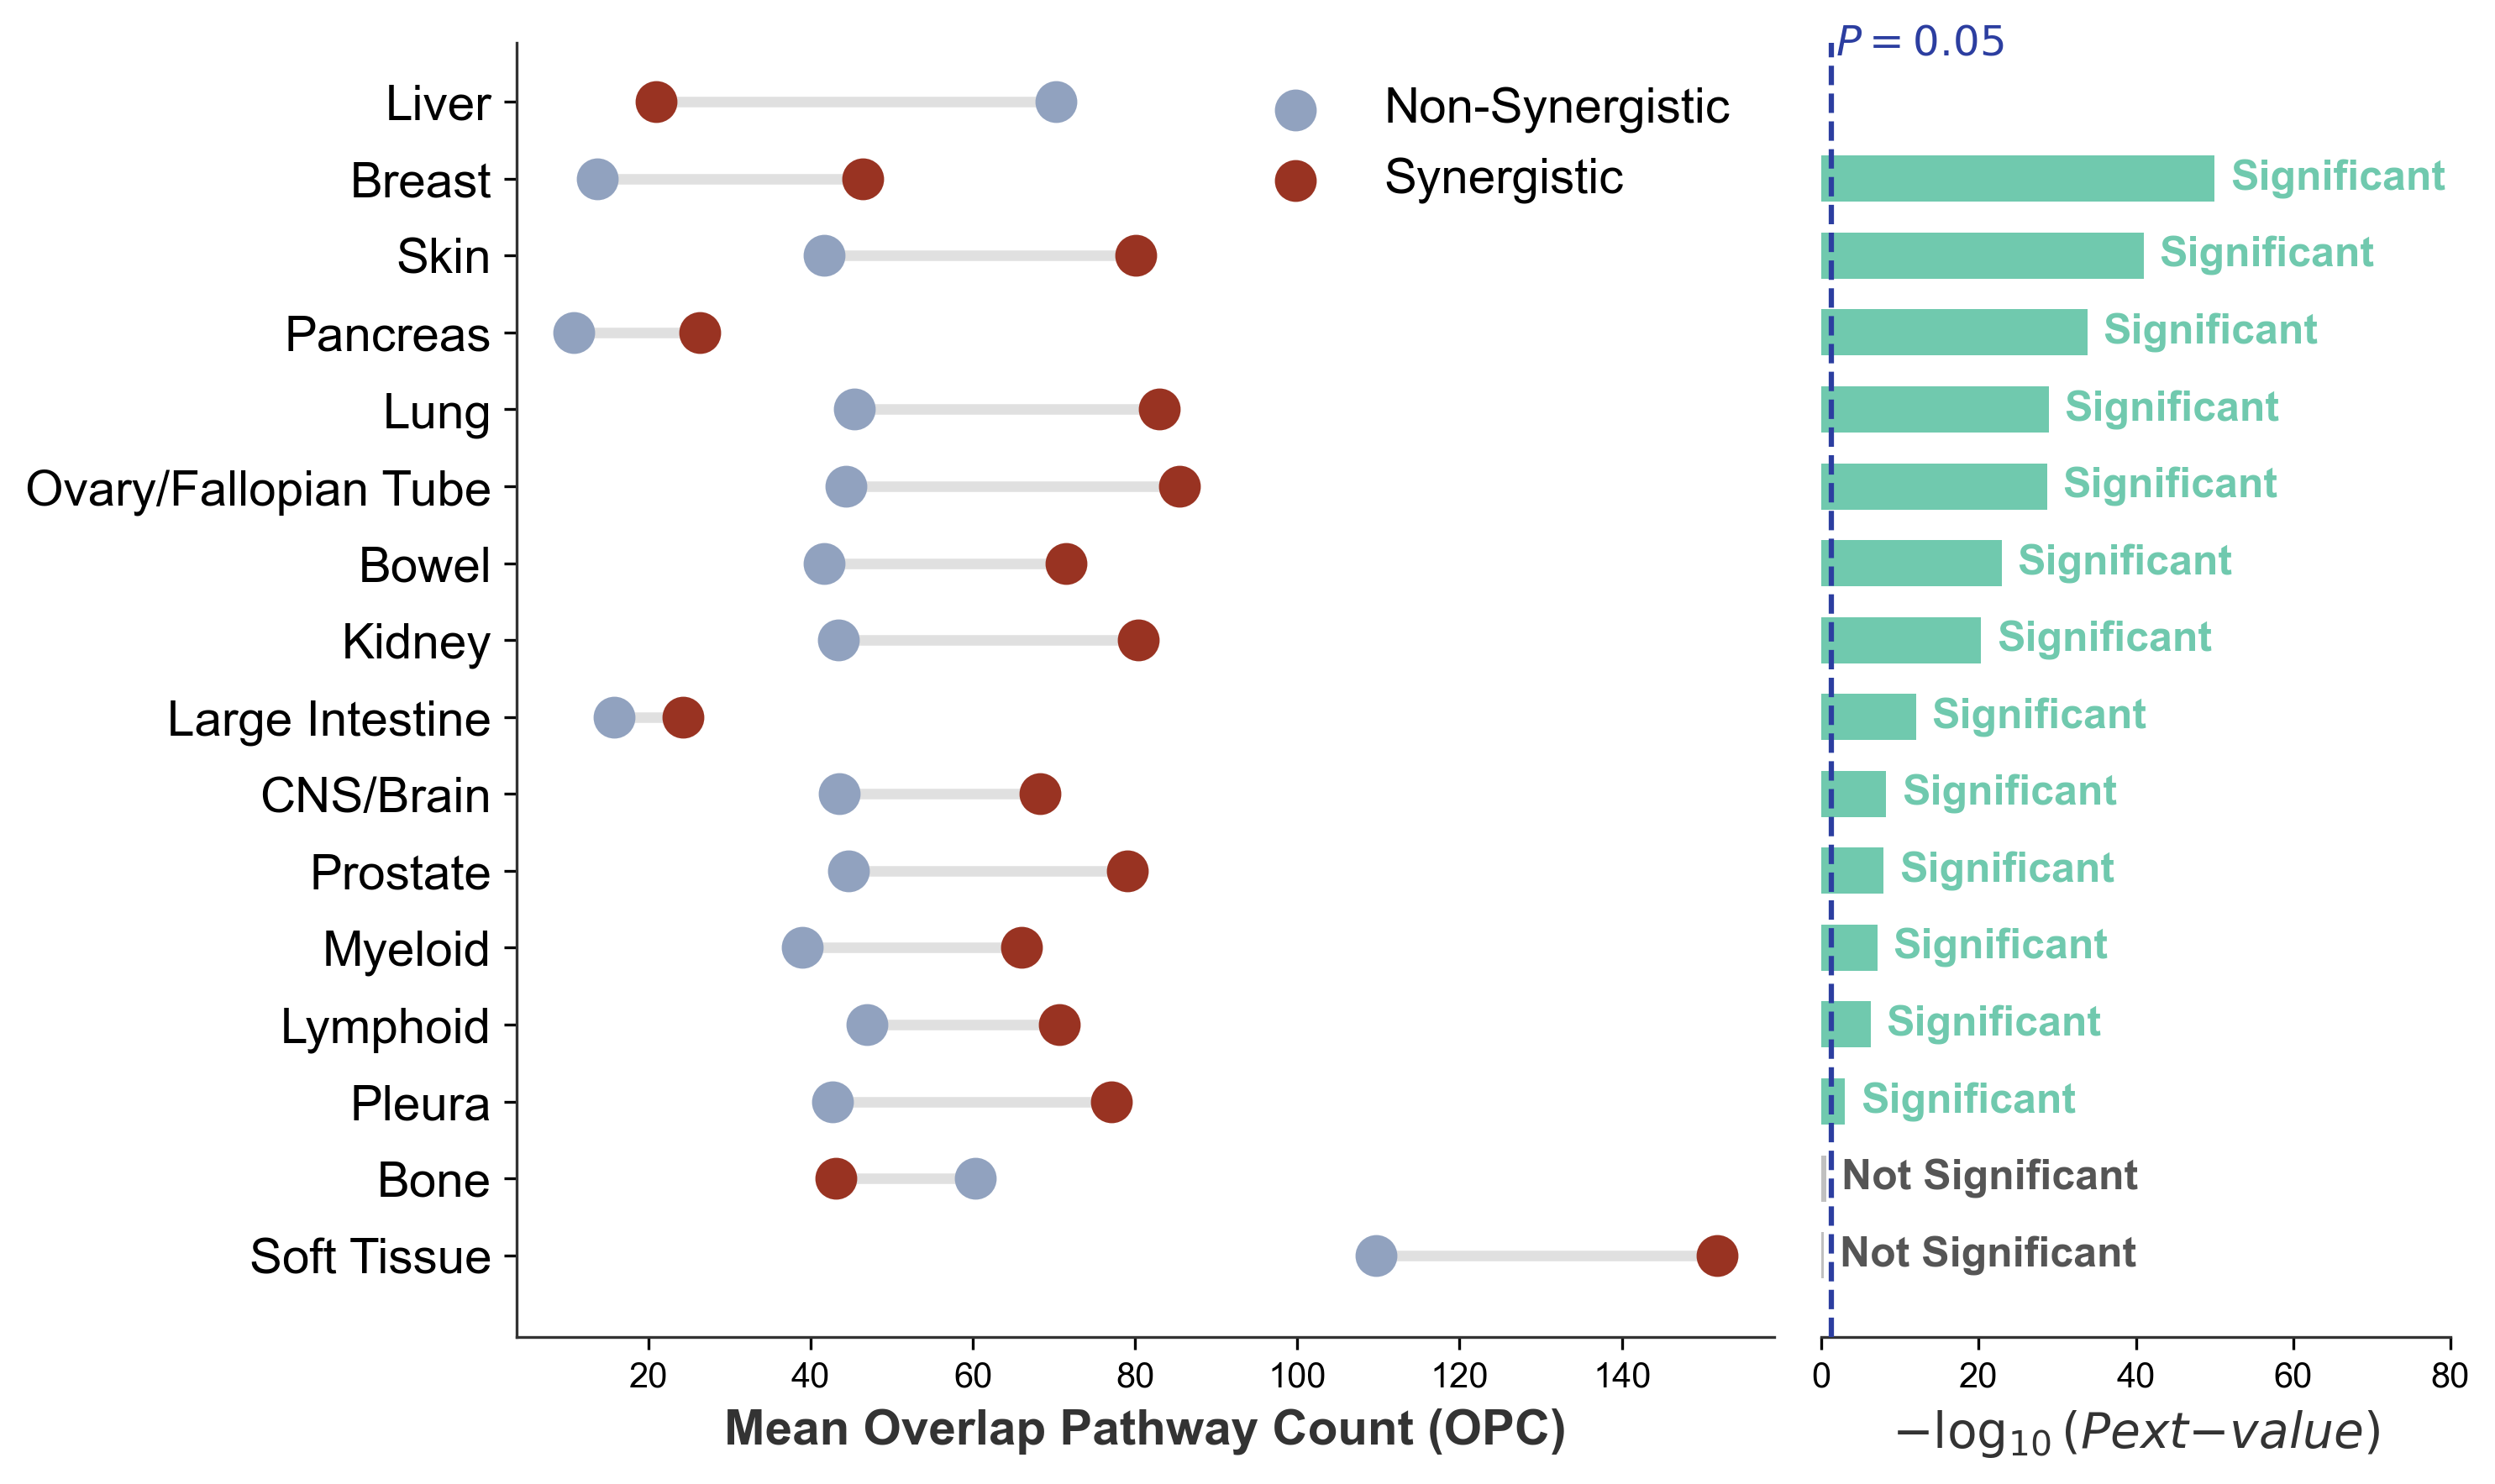

In [28]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import matplotlib.patches as mpatches

# ==========================================
# 1. 顶会风格与你的专属配色方案
# ==========================================
plt.rcParams["font.family"] = "sans-serif"
plt.rcParams["font.sans-serif"] = ["Arial", "Helvetica"]
plt.rcParams["pdf.fonttype"] = 42
plt.rcParams["ps.fonttype"] = 42

# 专属配色
COLOR_SYNERGY = "#993322"  # 深红 (代表 Synergy 均值，高亮)
COLOR_NOT_SYN = "#91A2BF"  # 灰蓝 (代表 Not Synergy 均值，作为背景基准)
COLOR_SIG = "#70C9AE"  # 青绿 (代表 P<0.05 达标)
COLOR_NS = "#C0C0C0"  # 银灰 (代表 P>=0.05 未达标)
COLOR_LINE = "#2C3EA0"  # 深蓝 (用于辅助线，如P=0.05的阈值线)

# ==========================================
# 2. 数据加载与预处理
# ==========================================
# 加载数据
df_means = pd.read_csv("../药物基因的路径关系/computer_by_Tissue.csv")
# p_score.csv 第一列没有列名，通常 pandas 会命名为 'Unnamed: 0'
df_p = pd.read_csv("../药物基因的路径关系/p_score.csv")
df_p.rename(columns={df_p.columns[0]: "Tissue"}, inplace=True)

# 合并数据
df = pd.merge(df_means, df_p, on="Tissue", how="inner")

# 过滤掉 Unknown 等不需要的标签 (根据你的论文，这里应该只展示具体的 12 个组织)
df = df[df["Tissue"].str.upper() != "UNKNOWN"].copy()

# 计算 -log10(p-value) 用于右侧面板绘图
# 避免 p=0 导致 log 报错，给极小值一个下限
df["p_value_plot"] = df["average_p_value"].apply(lambda x: max(x, 1e-50))
df["neg_log_p"] = -np.log10(df["p_value_plot"])

# 根据 Synergy 均值的增量或者 P-value 进行排序，这里推荐按 -log10(p) 排序
# 这样显著性最高的在最上面，不显著的(Bone, Liver等)自然沉到最下面
df.sort_values("neg_log_p", ascending=True, inplace=True)

# 组织名称列表与数据
tissues = df["Tissue"].tolist()
y_pos = np.arange(len(tissues))
syn_means = df["Synergy_mean"].values
not_syn_means = df["Not_Synergy_mean"].values
neg_log_p = df["neg_log_p"].values

# ==========================================
# 3. 绘制双面板图 (Left: Dumbbell, Right: P-value Bar)
# ==========================================
fig, (ax1, ax2) = plt.subplots(
    1, 2, figsize=(10, 6), sharey=True, gridspec_kw={"width_ratios": [2, 1]}, dpi=300
)

# --------- 左侧面板：哑铃图 (OPC Means) ---------
# 画连接线
ax1.hlines(
    y_pos, xmin=not_syn_means, xmax=syn_means, color="#E0E0E0", zorder=1, linewidth=3
)
# 画点
ax1.scatter(
    not_syn_means, y_pos, color=COLOR_NOT_SYN, s=120, zorder=2, label="Non-Synergistic"
)
ax1.scatter(syn_means, y_pos, color=COLOR_SYNERGY, s=120, zorder=2, label="Synergistic")

ax1.set_xlabel(
    "Mean Overlap Pathway Count (OPC)", fontsize=14, fontweight="bold", color="#333333"
)
ax1.set_yticks(y_pos)
ax1.set_yticklabels(tissues, fontsize=14)
ax1.spines["top"].set_visible(False)
ax1.spines["right"].set_visible(False)
ax1.spines["left"].set_color("#333333")
ax1.spines["bottom"].set_color("#333333")

# 添加图例 (左侧)
ax1.legend(loc="upper right", frameon=False, fontsize=14)

# --------- 右侧面板：P-value 柱状图 ---------
# 定义阈值 (-log10(0.05) 约等于 1.301)
threshold = -np.log10(0.05)

# 根据是否达标分配颜色
bar_colors = [COLOR_SIG if val >= threshold else COLOR_NS for val in neg_log_p]

bars = ax2.barh(y_pos, neg_log_p, color=bar_colors, height=0.6, zorder=2)

# 画 P=0.05 的虚线
ax2.axvline(x=threshold, color=COLOR_LINE, linestyle="--", linewidth=1.5, zorder=3)
# 在阈值线上方添加文本标注
ax2.text(
    threshold + 0.5,
    len(tissues) - 0.5,
    "$P=0.05$",
    color=COLOR_LINE,
    fontsize=12,
    va="bottom",
)

ax2.set_xlabel(
    "$-\log_{10}(P\text{-value})$", fontsize=14, fontweight="bold", color="#333333"
)
ax2.spines["top"].set_visible(False)
ax2.spines["right"].set_visible(False)
ax2.spines["left"].set_visible(False)  # 隐藏左边框，让两个图显得更连贯
ax2.spines["bottom"].set_color("#333333")
ax2.tick_params(axis="y", length=0)  # 隐藏右侧的 y 轴刻度线

# --- 修改：将 * 和 ns 替换为直观的英文全称 ---
for i, bar in enumerate(bars):
    width = bar.get_width()
    p_val = df["average_p_value"].iloc[i]
    if p_val >= 0.05:
        text = "Not Significant"
        color = "#555555"  # 使用深灰色显得更柔和
    else:
        text = "Significant"
        color = COLOR_SIG  # 颜色与柱子保持一致

    # 在柱子右侧标注，并稍微调小字号 (fontsize=10) 保持版面整洁
    ax2.text(
        width + (max(neg_log_p) * 0.04),
        bar.get_y() + bar.get_height() / 2,
        text,
        va="center",
        color=color,
        fontsize=12,
        fontweight="bold",
    )

# 【关键】因为单词较长，手动扩展右侧 X 轴的上限，防止文字被图表边缘裁切
ax2.set_xlim(0, max(neg_log_p) * 1.6)

plt.tight_layout()
plt.savefig("Tissue_Pathway_Overlap.pdf", bbox_inches="tight", transparent=True)
plt.savefig(
    "Tissue_Pathway_Overlap.png", dpi=300, bbox_inches="tight", transparent=True
)
plt.show()

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import matplotlib.patches as mpatches

# ==========================================
# 1. 顶会风格与你的专属配色方案
# ==========================================
plt.rcParams["font.family"] = "sans-serif"
plt.rcParams["font.sans-serif"] = ["Arial", "Helvetica"]
plt.rcParams["pdf.fonttype"] = 42
plt.rcParams["ps.fonttype"] = 42

# 专属配色
COLOR_SYNERGY = "#993322"  # 深红 (代表 Synergy 均值，高亮)
COLOR_NOT_SYN = "#91A2BF"  # 灰蓝 (代表 Not Synergy 均值，作为背景基准)
COLOR_SIG = "#70C9AE"  # 青绿 (代表 P<0.05 达标)
COLOR_NS = "#C0C0C0"  # 银灰 (代表 P>=0.05 未达标)
COLOR_LINE = "#2C3EA0"  # 深蓝 (用于辅助线，如P=0.05的阈值线)

# ==========================================
# 2. 数据加载与预处理
# ==========================================
# 加载数据
df_means = pd.read_csv("../药物基因与基因路径之间/computer_by_Tissue.csv")
# p_score.csv 第一列没有列名，通常 pandas 会命名为 'Unnamed: 0'
df_p = pd.read_csv("../药物基因与基因路径之间/p_score.csv")
df_p.rename(columns={df_p.columns[0]: "Tissue"}, inplace=True)

# 合并数据
df = pd.merge(df_means, df_p, on="Tissue", how="inner")

# 过滤掉 Unknown 等不需要的标签 (根据你的论文，这里应该只展示具体的 12 个组织)
df = df[df["Tissue"].str.upper() != "UNKNOWN"].copy()

# 计算 -log10(p-value) 用于右侧面板绘图
# 避免 p=0 导致 log 报错，给极小值一个下限
df["p_value_plot"] = df["average_p_value"].apply(lambda x: max(x, 1e-50))
df["neg_log_p"] = -np.log10(df["p_value_plot"])

# 根据 Synergy 均值的增量或者 P-value 进行排序，这里推荐按 -log10(p) 排序
# 这样显著性最高的在最上面，不显著的(Bone, Liver等)自然沉到最下面
df.sort_values("neg_log_p", ascending=True, inplace=True)

# 组织名称列表与数据
tissues = df["Tissue"].tolist()
y_pos = np.arange(len(tissues))
syn_means = df["Synergy_mean"].values
not_syn_means = df["Not_Synergy_mean"].values
neg_log_p = df["neg_log_p"].values

# ==========================================
# 3. 绘制双面板图 (Left: Dumbbell, Right: P-value Bar)
# ==========================================
fig, (ax1, ax2) = plt.subplots(
    1, 2, figsize=(10, 6), sharey=True, gridspec_kw={"width_ratios": [2, 1]}, dpi=300
)

# --------- 左侧面板：哑铃图 (OPC Means) ---------
# 画连接线
ax1.hlines(
    y_pos, xmin=not_syn_means, xmax=syn_means, color="#E0E0E0", zorder=1, linewidth=3
)
# 画点
ax1.scatter(
    not_syn_means, y_pos, color=COLOR_NOT_SYN, s=120, zorder=2, label="Non-Synergistic"
)
ax1.scatter(syn_means, y_pos, color=COLOR_SYNERGY, s=120, zorder=2, label="Synergistic")

ax1.set_xlabel(
    "Mean Overlap Pathway Count (OPC)", fontsize=14, fontweight="bold", color="#333333"
)
ax1.set_yticks(y_pos)
ax1.set_yticklabels(tissues, fontsize=14)
ax1.spines["top"].set_visible(False)
ax1.spines["right"].set_visible(False)
ax1.spines["left"].set_color("#333333")
ax1.spines["bottom"].set_color("#333333")

# 添加图例 (左侧)
ax1.legend(loc="upper right", frameon=False, fontsize=14)

# --------- 右侧面板：P-value 柱状图 ---------
# 定义阈值 (-log10(0.05) 约等于 1.301)
threshold = -np.log10(0.05)

# 根据是否达标分配颜色
bar_colors = [COLOR_SIG if val >= threshold else COLOR_NS for val in neg_log_p]

bars = ax2.barh(y_pos, neg_log_p, color=bar_colors, height=0.6, zorder=2)

# 画 P=0.05 的虚线
ax2.axvline(x=threshold, color=COLOR_LINE, linestyle="--", linewidth=1.5, zorder=3)
# 在阈值线上方添加文本标注
ax2.text(
    threshold + 0.5,
    len(tissues) - 0.5,
    "$P=0.05$",
    color=COLOR_LINE,
    fontsize=12,
    va="bottom",
)

ax2.set_xlabel(
    "$-\log_{10}(P\text{-value})$", fontsize=14, fontweight="bold", color="#333333"
)
ax2.spines["top"].set_visible(False)
ax2.spines["right"].set_visible(False)
ax2.spines["left"].set_visible(False)  # 隐藏左边框，让两个图显得更连贯
ax2.spines["bottom"].set_color("#333333")
ax2.tick_params(axis="y", length=0)  # 隐藏右侧的 y 轴刻度线

# --- 修改：将 * 和 ns 替换为直观的英文全称 ---
for i, bar in enumerate(bars):
    width = bar.get_width()
    p_val = df["average_p_value"].iloc[i]
    if p_val >= 0.05:
        text = "Not Significant"
        color = "#555555"  # 使用深灰色显得更柔和
    else:
        text = "Significant"
        color = COLOR_SIG  # 颜色与柱子保持一致

    # 在柱子右侧标注，并稍微调小字号 (fontsize=10) 保持版面整洁
    ax2.text(
        width + (max(neg_log_p) * 0.04),
        bar.get_y() + bar.get_height() / 2,
        text,
        va="center",
        color=color,
        fontsize=12,
        fontweight="bold",
    )

# 【关键】因为单词较长，手动扩展右侧 X 轴的上限，防止文字被图表边缘裁切
ax2.set_xlim(0, max(neg_log_p) * 1.6)

plt.tight_layout()
plt.savefig("Tissue_Pathway_Overlap.pdf", bbox_inches="tight", transparent=True)
plt.savefig(
    "Tissue_Pathway_Overlap.png", dpi=300, bbox_inches="tight", transparent=True
)
plt.show()